In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl
import seaborn as sns
import gseapy as gp
from tqdm.auto import tqdm
from pathlib import Path
import yaml

In [5]:
config = yaml.safe_load(open("../configuration/config.yaml"))
perturbation_colors = config['perturbation_colors']
cell_lines = config['cell_lines']
cell_line_colors = config['cell_line_colors']
perturbations = config['perturbations']
actual_perturbations = config['actual_perturbations']
DIR = Path(config['DIR'])

# Count Data Analysis

In [153]:
df_vst = pd.read_csv("../results/count_matrix_vst.csv", header=0, index_col=0)
coldata = pd.read_csv("../results/coldata.tsv", sep='\t', header=0, index_col=0)

In [154]:
coldata.perturbation.unique()

array(['FBL', 'FTL', 'MALAT1', 'MOCK', 'NEAT1', 'NT', 'RUBY', 'SNHG15',
       'SNHG16', 'VIM', 'LINC', 'PPIA'], dtype=object)

In [155]:
coldata.head()

,line,genotype,perturbation,guide,replicate
75CAS_FBL_V1_R1,H1975,CAS,FBL,1.0,R1
75CAS_FBL_V1_R2,H1975,CAS,FBL,1.0,R2
75CAS_FBL_V1_R3,H1975,CAS,FBL,1.0,R3
75CAS_FBL_V2_R1,H1975,CAS,FBL,2.0,R1
75CAS_FBL_V2_R2,H1975,CAS,FBL,2.0,R2


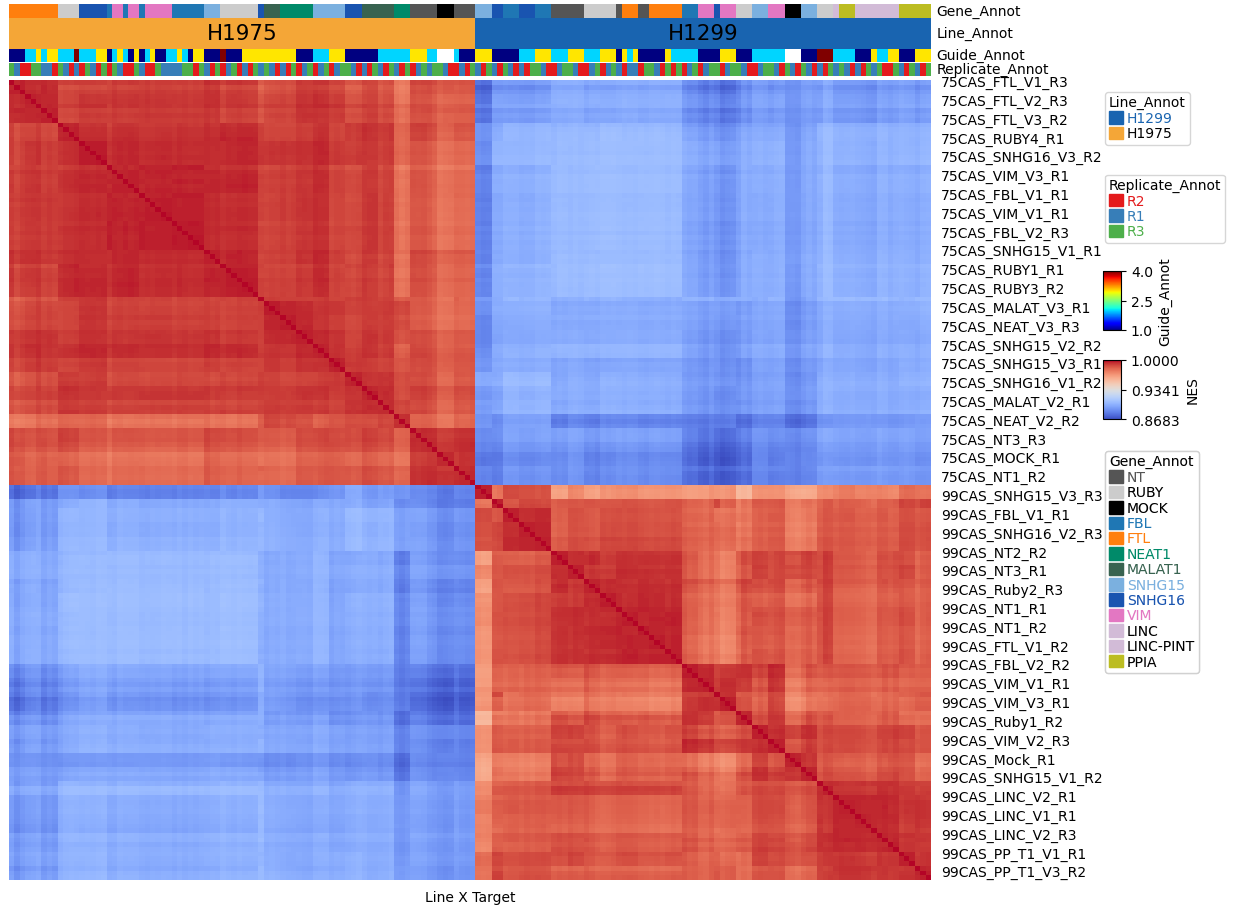

In [156]:
import PyComplexHeatmap as pch
corr = df_vst.corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(coldata.perturbation, add_text=False, colors=perturbation_colors),
    Line_Annot=pch.anno_simple(coldata.line, add_text=True, colors=cell_line_colors, height=7),
    Guide_Annot=pch.anno_simple(coldata.guide, add_text=False),
    Replicate_Annot=pch.anno_simple(coldata.replicate, add_text=False),
    axis=1, verbose=0,
)

# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=True,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    # left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Line X Target", label='NES',
)

Incresing ncol
Incresing ncol
More than 3 cols is not supported
Legend too long, generating a new column..


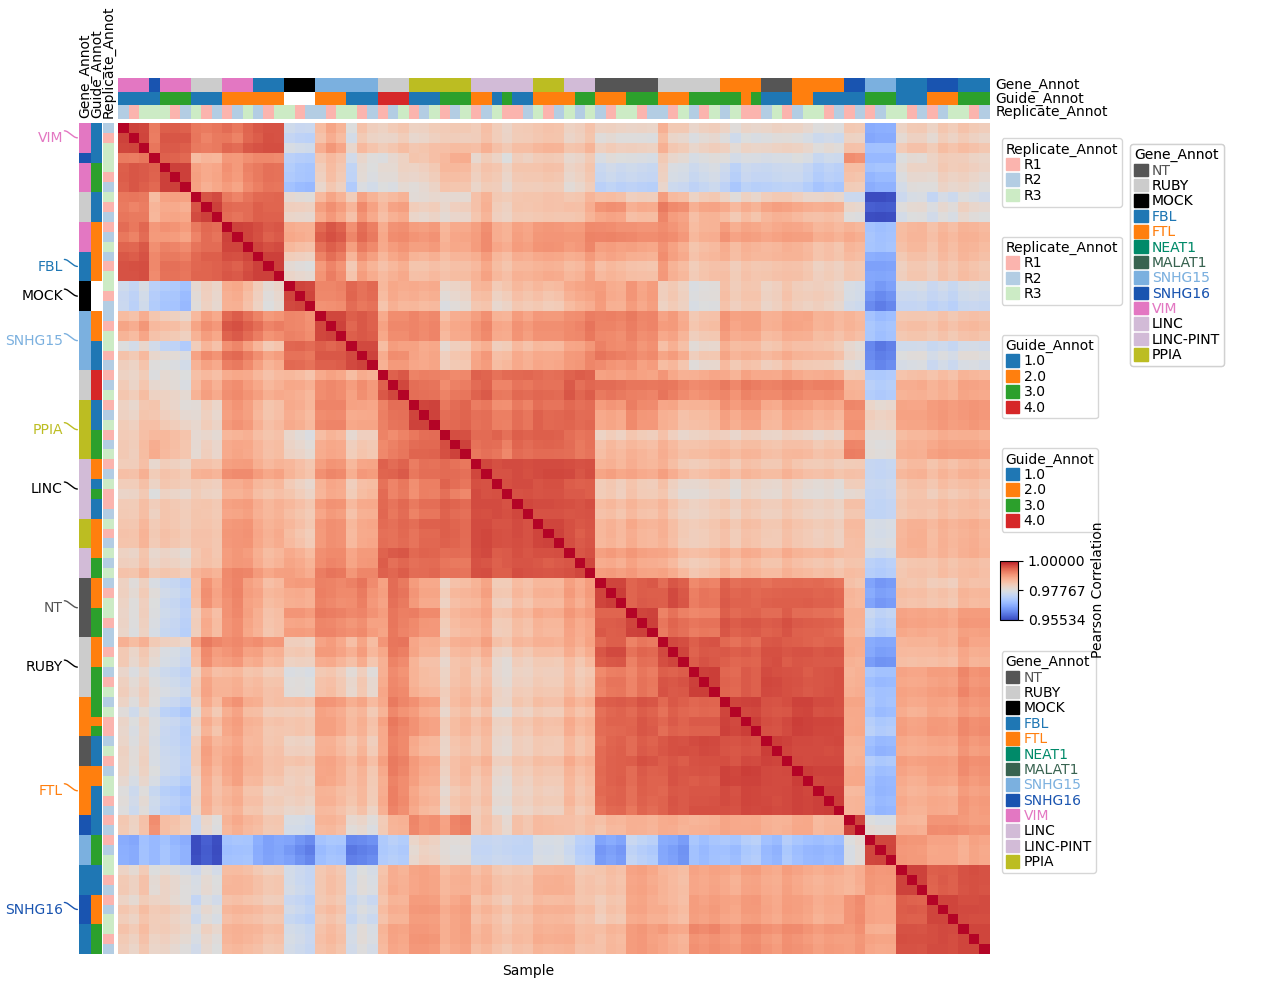

In [157]:
import PyComplexHeatmap as pch

scolData = coldata[coldata.line == 'H1299']
corr = df_vst[scolData.index].corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=1, verbose=0,
)
row_annotations = pch.HeatmapAnnotation(
    Gene_Label=pch.anno_label(scolData.perturbation, merge=True, colors=perturbation_colors),
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=0, verbose=0,
)
# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=False,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Sample", label='Pearson Correlation',
)

In [158]:
import PyComplexHeatmap as pch

scolData = coldata[coldata.line == 'H1975']
corr = df_vst[scolData.index].corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=1, verbose=0,
)
row_annotations = pch.HeatmapAnnotation(
    Gene_Label=pch.anno_label(scolData.perturbation, merge=True, colors=perturbation_colors),
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=0, verbose=0,
)
# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=False,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Sample", label='Pearson Correlation',
)

KeyError: "['75WT_RUBY4_R2', '75WT_RUBY4_R3'] not in index"

/tmp/ipykernel_813925/3571805531.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'N/A' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  pca_df.loc[pca_df.perturbation=='MOCK', 'guide'] = 'N/A'  # Otherwise there is no plots made for MOCK


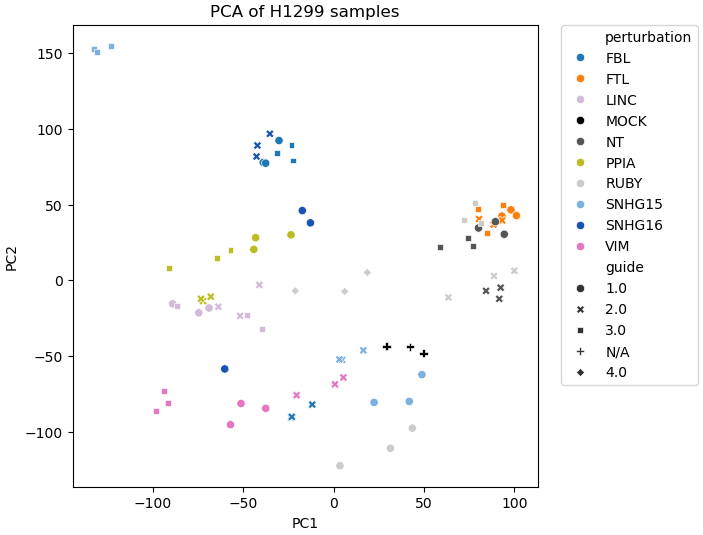

In [162]:
# PCA plot
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

for line in ['H1299']: # 'H1975'
    scolData = coldata[coldata.line == line]
    embedding = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(df_vst[scolData.index].T))
    pca_df = pd.DataFrame(embedding, columns=['PC1', 'PC2'], index=scolData.index).join(scolData)
    pca_df.loc[pca_df.perturbation=='MOCK', 'guide'] = 'N/A'  # Otherwise there is no plots made for MOCK
    fig, ax = pl.subplots(figsize=(6, 6))
    sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='perturbation', style='guide', palette=perturbation_colors, ax=ax)
    ax.set_title(f'PCA of {line} samples')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    pl.show()

# Vis Deseq2 results

In [292]:
# Aggregate DESeq2 results
res = {}
for cell_line in cell_lines:
    for file in Path(f"../results/deseq2/{cell_line}").glob("*_deseq2_results.csv"):
        gene = file.stem.split("_")[0]
        gene = 'LINC-PINT' if gene == 'LINC' else gene
        df = pd.read_csv(file, index_col=0)
        res[(cell_line, gene)] = df
tab = pd.concat(res, axis=1)

In [294]:
tab.head()

H1299                                                   \
              RUBY                                                    
          baseMean log2FoldChange     lfcSE      stat        pvalue   
DUSP1   858.961652       0.674525  0.090974  8.402059  4.387159e-17   
LPIN1  1581.282665      -0.686709  0.090393 -7.669322  1.729074e-14   
H6PD    459.571057      -0.777543  0.094507 -7.631514  2.320126e-14   
TFPI2   565.042829       0.602007  0.082489  7.323349  2.418583e-13   
BIRC3  2549.241789       0.800965  0.098846  7.143354  9.108074e-13   

                                                                     ...  \
                            MOCK                                     ...   
               padj     baseMean log2FoldChange     lfcSE      stat  ...   
DUSP1  7.329626e-13   858.961652      -0.220721  0.161672  0.337948  ...   
LPIN1  1.292078e-10  1581.282665      -0.117443  0.158166 -1.658734  ...   
H6PD   1.292078e-10   459.571057       0.628152  0.166176  2.790806  ...   
TFPI2  1.010182e-09   565.042829      -0.457321  0.143213 -2.230685  ...   
BIRC3  3.043372e-09  2549.241789      -1.515710  0.181615 -7.064449  ...   

          H1975                                                      \
         SNHG15                                                MOCK   
          lfcSE       stat        pvalue          padj     baseMean   
DUSP1  0.081031  -0.429233  6.677534e-01  7.663206e-01  1502.881665   
LPIN1  0.056329  -3.497965  4.688234e-04  1.540516e-03   705.166118   
H6PD   0.052450   0.213861  8.306554e-01  8.898178e-01   490.828536   
TFPI2  0.117498   4.941377  7.757267e-07  4.041138e-06   175.163311   
BIRC3  0.110293  12.035061  2.324607e-33  3.855154e-31   167.740638   

                                                              
                                                              
      log2FoldChange     lfcSE      stat    pvalue      padj  
DUSP1       0.307365  0.103253  2.616111  0.008894  0.054774  
LPIN1       0.178211  0.075946  2.214772  0.026776  0.118217  
H6PD        0.306888  0.071220  4.243600  0.000022  0.000434  
TFPI2      -0.274105  0.133048 -0.875508  0.381298  0.629497  
BIRC3      -0.529055  0.135269 -1.289705  0.197153  0.430249  

[5 rows x 96 columns]

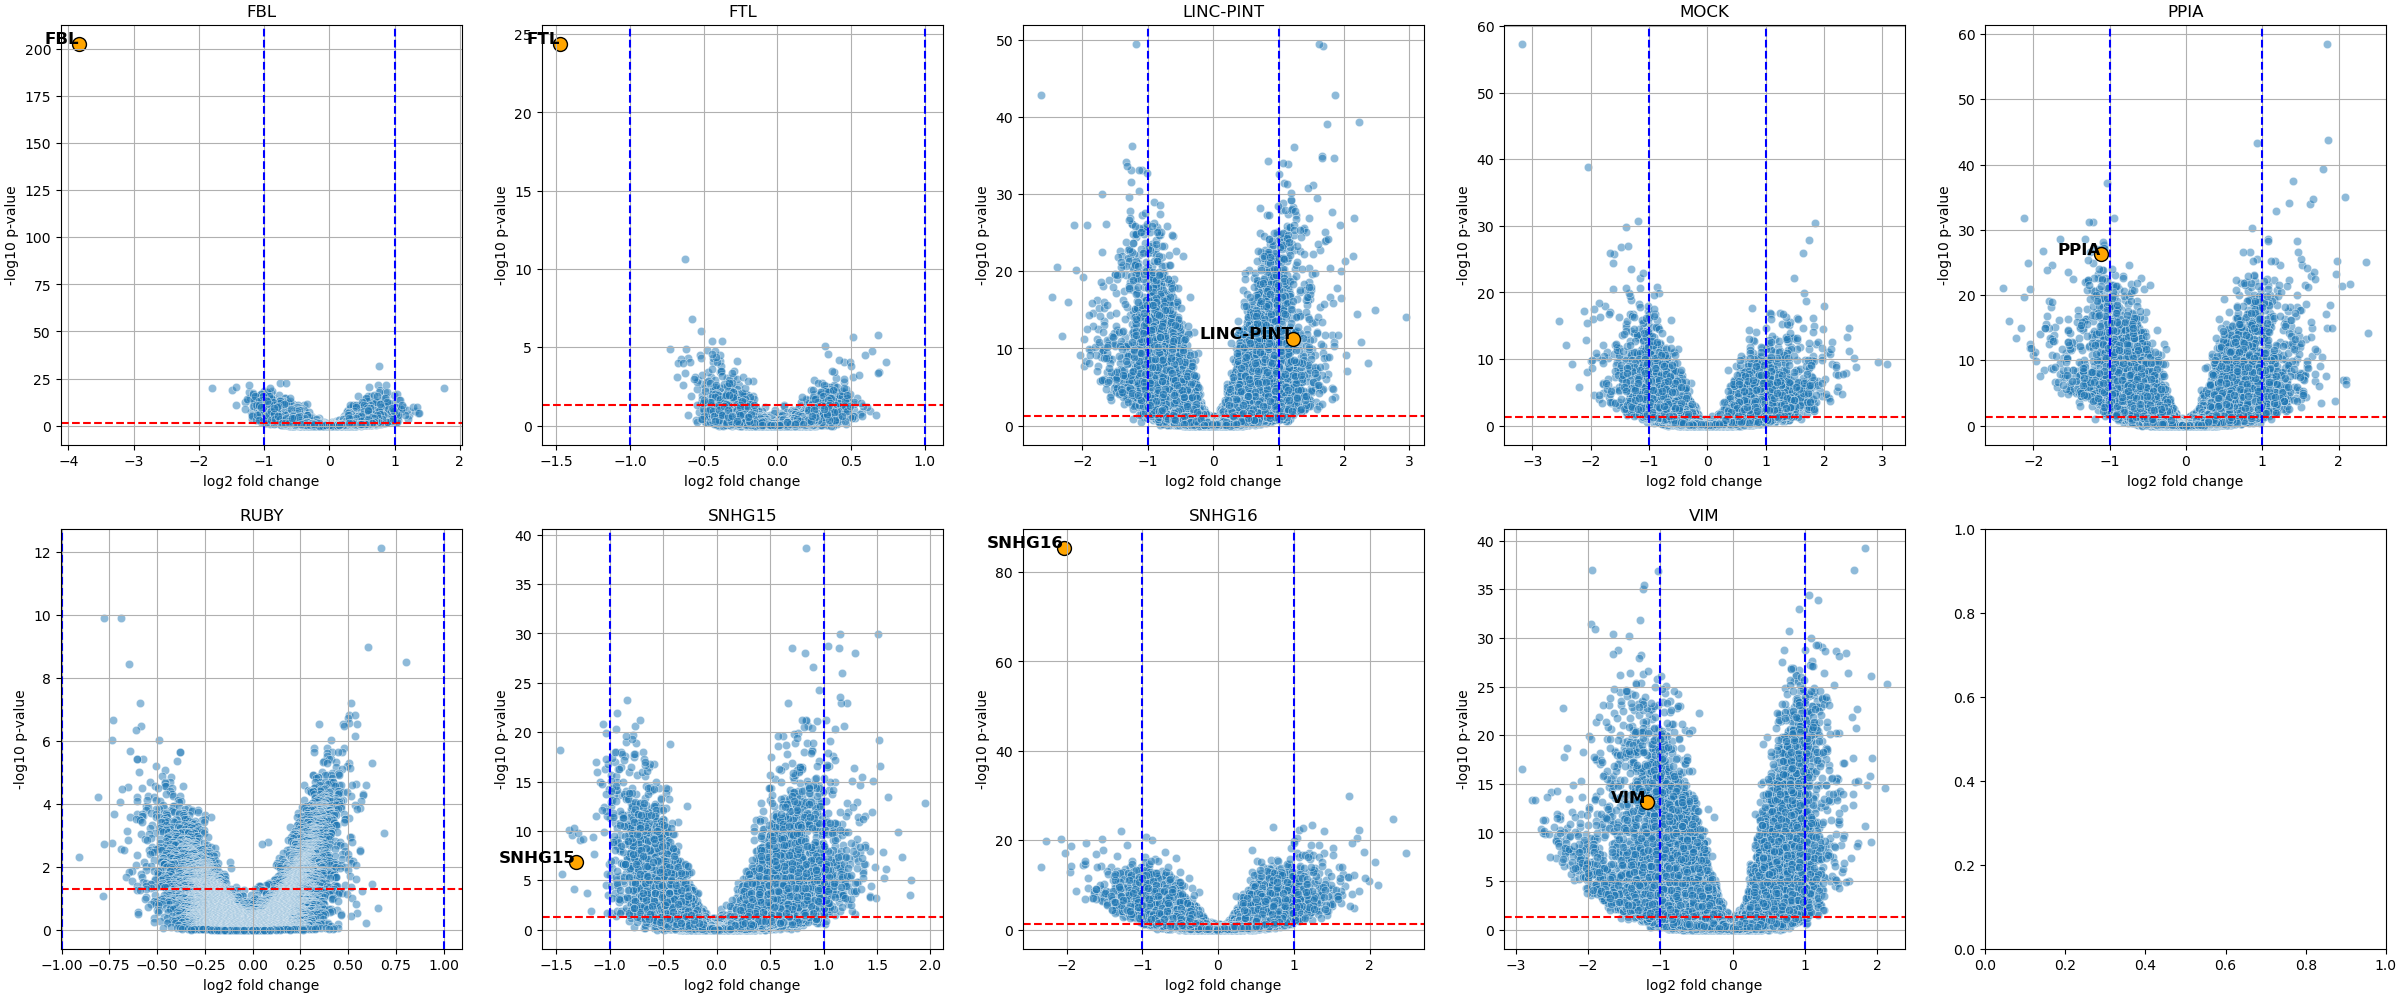

/home/peidli/miniconda3/envs/py_env/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_813925/970967543.py:21: RuntimeWarning: divide by zero encountered in log10
  ax.scatter(target_df['log2FoldChange'], -np.log10(target_df['padj']), color='orange', s=100, edgecolor='black')
/tmp/ipykernel_813925/970967543.py:22: RuntimeWarning: divide by zero encountered in log10
  ax.text(target_df['log2FoldChange'], -np.log10(target_df['padj']), gene, fontsize=12, weight='bold', ha='right')
posx and posy should be finite values
posx and posy should be finite values


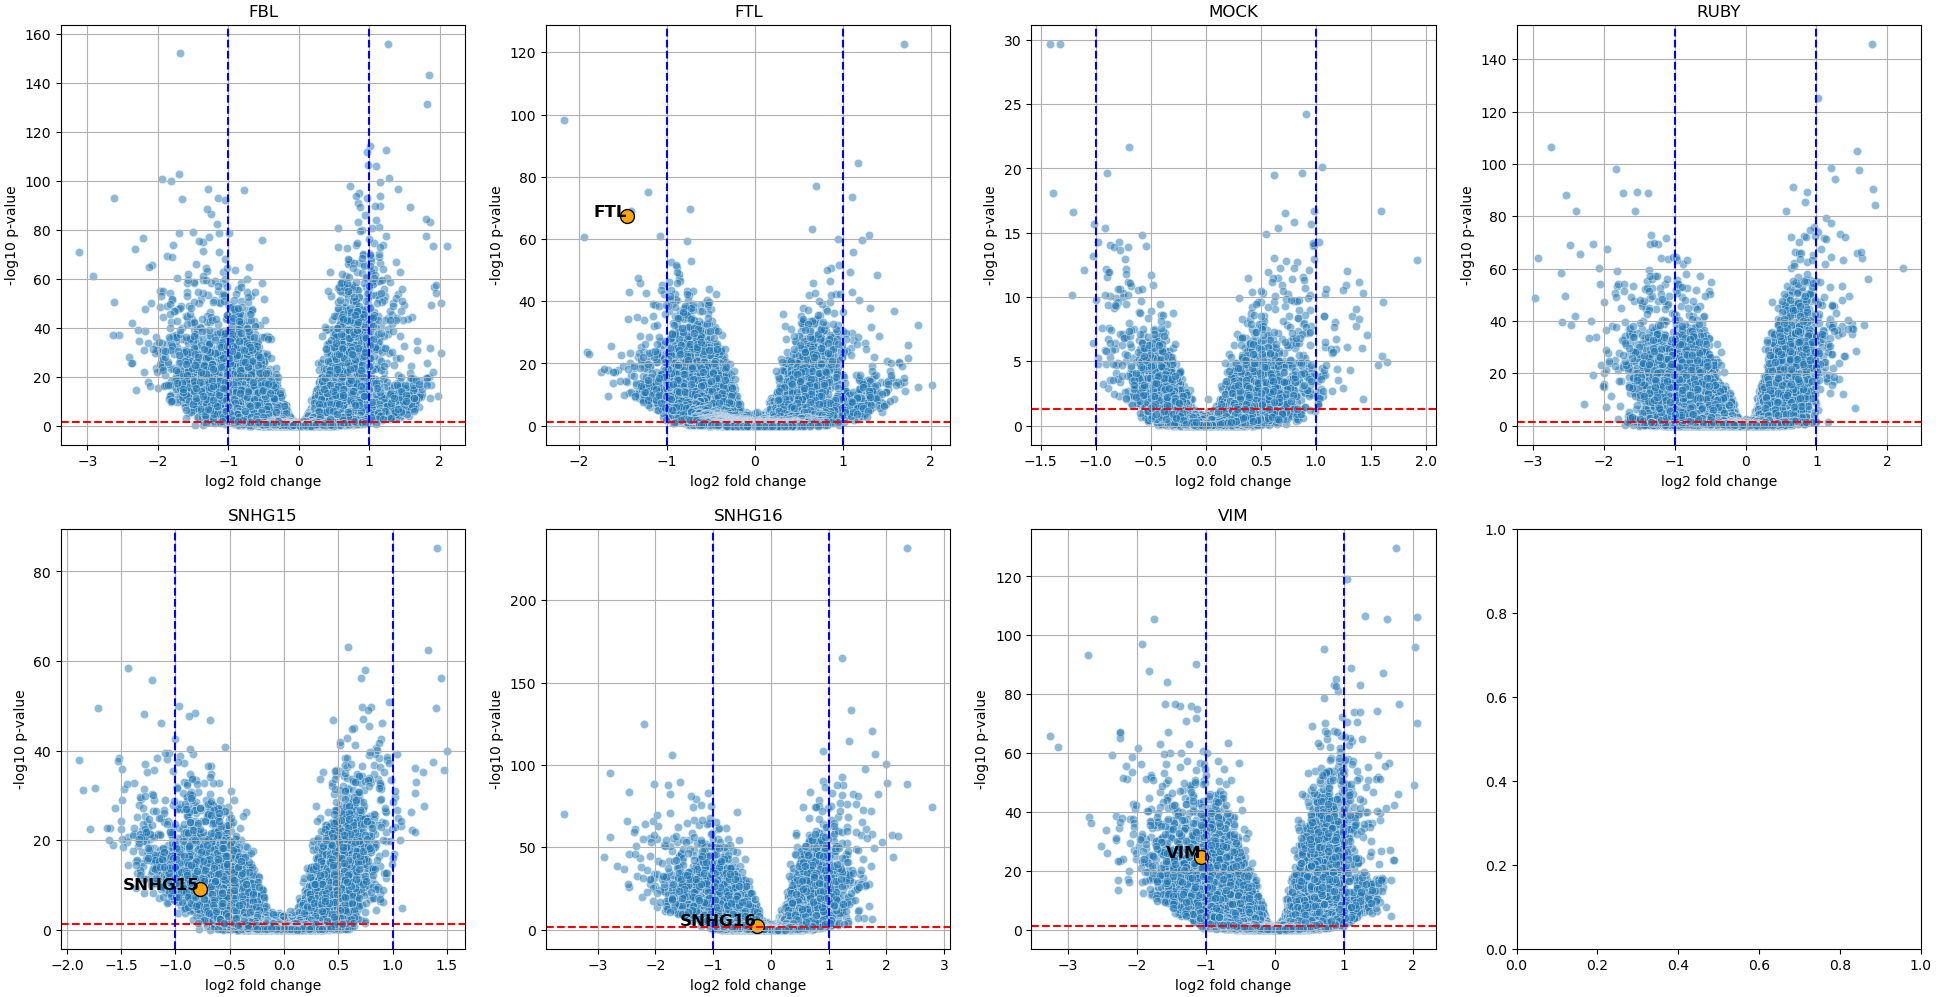

In [295]:
# Vulcano plot per target gene
for cell_line in cell_lines:
    stab = tab[cell_line]
    genes = sorted(list(stab.columns.get_level_values(0).unique()))
    nrows = 2
    ncols = int(np.ceil(len(genes)/nrows))
    fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
    for ax, gene in zip(axs.flat, genes):
        df = stab[gene]
        sns.scatterplot(data=df, x='log2FoldChange', y=-np.log10(df['padj']), alpha=0.5, ax=ax)
        ax.set_title(gene)
        ax.set_xlabel('log2 fold change')
        ax.set_ylabel('-log10 p-value')
        ax.axhline(-np.log10(0.05), color='red', linestyle='--')
        ax.axvline(1, color='blue', linestyle='--')
        ax.axvline(-1, color='blue', linestyle='--')
        ax.grid(True)
        # Mark target gene
        if gene in df.index:
            target_df = df.loc[gene]
            ax.scatter(target_df['log2FoldChange'], -np.log10(target_df['padj']), color='orange', s=100, edgecolor='black')
            ax.text(target_df['log2FoldChange'], -np.log10(target_df['padj']), gene, fontsize=12, weight='bold', ha='right')
    pl.show()

In [109]:
vals = {}
for cell_line in cell_lines:
    stab = tab[cell_line]
    genes = sorted(list(stab.columns.get_level_values(0).unique()))
    for gene in genes:
        if gene in stab[gene].index:
            df = stab[gene].loc[gene]
            vals[(cell_line, gene)] = df
kd = pd.concat(vals, axis=1).T
kd.reset_index(names=['Cell_Line', 'Gene'], inplace=True)

In [110]:
kd

,Cell_Line,Gene,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
0,H1299,FBL,11127.242546,-3.835043,0.109152,-30.766463,7.365395e-208,1.592693e-203
1,H1299,FTL,13741.024269,-1.474306,0.103427,-11.238664,2.633371e-29,4.111746e-25
2,H1299,LINC-PINT,48.657180,1.222083,0.161422,7.285528,3.204140e-13,5.566685e-12
3,H1299,PPIA,30560.435278,-1.112046,0.087234,-11.339779,8.335438e-30,5.703156e-27
4,H1299,SNHG15,630.069898,-1.315952,0.156107,-5.767931,8.025064e-09,1.393231e-07
5,H1299,SNHG16,2227.131869,-2.036103,0.094360,-20.172382,1.711932e-90,3.795352e-86
6,H1299,VIM,71893.327589,-1.188886,0.134436,-7.849443,4.178894e-15,7.686167e-14
7,H1975,FBL,1404.451686,-3.046967,0.058554,-50.963417,0.000000e+00,0.000000e+00
8,H1975,FTL,9606.495937,-1.447256,0.076857,-17.870087,2.016793e-71,5.740466e-68
9,H1975,SNHG15,1015.119458,-0.775967,0.109069,-6.478706,9.251262e-11,8.291700e-10


/home/peidli/miniconda3/envs/py_env/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_813925/713873621.py:22: RuntimeWarning: divide by zero encountered in log10
  ax.annotate(row['Gene'], (row['log2FoldChange']+0.1, -np.log10(row['padj'])), fontsize=6)


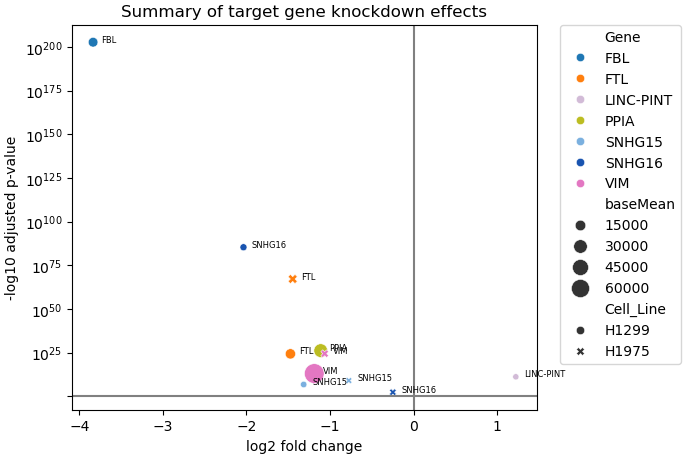

In [152]:
fig, ax = pl.subplots(figsize=(6, 5))
sns.scatterplot(data=kd, x='log2FoldChange', y=-np.log10(kd['padj']), style='Cell_Line', 
                hue='Gene', size='baseMean', palette=perturbation_colors,
                sizes=(20, 200), ax=ax
                )
# ax.axhline(-np.log10(0.05), color='red', linestyle='--')
ax.axvline(0, color='grey', linestyle='-')
ax.axhline(0, color='grey', linestyle='-')
# change y-axis labels to log scale
from matplotlib.ticker import FuncFormatter
def log_10_formatter(x, pos):
    if x <= 0:
        return ""
    else:
        return f"$10^{{{int(x)}}}$"
ax.yaxis.set_major_formatter(FuncFormatter(log_10_formatter))
ax.set_ylabel('-log10 adjusted p-value')
ax.set_xlabel('log2 fold change')
ax.set_title('Summary of target gene knockdown effects')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
for _, row in kd.iterrows():
    ax.annotate(row['Gene'], (row['log2FoldChange']+0.1, -np.log10(row['padj'])), fontsize=6)
pl.show()

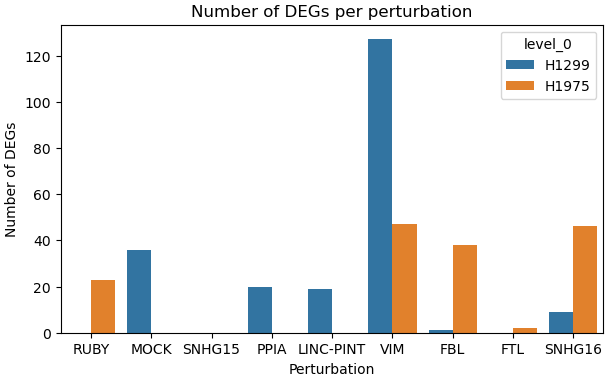

In [321]:
# Number of DEGs per perturbation
pval_ok = (tab.loc[:, (slice(None), slice(None), 'padj')] < 0.01)
is_high = (tab.loc[:, (slice(None), slice(None), 'log2FoldChange')].abs() > 2)
sel = pd.DataFrame(pval_ok.values & is_high.values, index=pval_ok.index, columns=pval_ok.columns)
fig, ax = pl.subplots(figsize=(7, 4))
data=sel.sum().reset_index()
sns.barplot(data, x='level_1', y=0, hue='level_0')
ax.set_ylabel('Number of DEGs')
ax.set_xlabel('Perturbation')
ax.set_title('Number of DEGs per perturbation')
pl.show()

# GSEA

In [183]:
# For each perturbation and cell line, use the DEGs from Wilcoxon rank-sum test
# We accept that the resulting gene lists are heavily enriched with FDR genes,
# since we just want to run GSEA on top of it.
results = {}
for cell_line in cell_lines:
    genes = list(tab[cell_line].columns.get_level_values(0).unique())
    # for cell_line in tqdm(cell_lines):
    for gene in tqdm(genes, desc=cell_line):
        df = tab[cell_line][gene].copy().reset_index(names=['gene'])
        df['scores'] = -np.log10(df['padj']) * np.sign(df['log2FoldChange'])
        df.sort_values('scores', inplace=True)
        # drop NaN
        df = df[~df['scores'].isna()]
        # drop duplicated scores, ties are not allowed
        df = df[~df['scores'].duplicated()]
        # GSEA Prerank
        pre_res = gp.prerank(rnk=df[['gene', 'scores']],
                        gene_sets='MSigDB_Hallmark_2020',#,KEGG_2021_Human',
                        threads=4,
                        min_size=5,
                        max_size=1000,
                        permutation_num=100,
                        outdir=None, # don't write to disk
                        seed=42,
                        verbose=False,
                        no_plot=True,
                    )
        results[(cell_line, gene)] = pre_res.res2d

H1299:   0%|          | 0/9 [00:00<?, ?it/s]

H1975:   0%|          | 0/7 [00:00<?, ?it/s]

/home/peidli/miniconda3/envs/py_env/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
2025-09-09 11:27:26,884 [WARNING] Input gene rankings contains inf values!
/home/peidli/miniconda3/envs/py_env/lib/python3.9/site-packages/gseapy/gsea.py:507: FutureWarning: The 'method' keyword in Series.replace is deprecated and will be removed in a future version.
  rankser.replace(-np.inf, method="ffill", inplace=True)
/home/peidli/miniconda3/envs/py_env/lib/python3.9/site-packages/gseapy/gsea.py:508: FutureWarning: The 'method' keyword in Series.replace is deprecated and will be removed in a future version.
  rankser.replace(np.inf, method="bfill", inplace=True)
2025-09-09 11:27:26,886 [WARNING] Duplicated values found in preranked stats: 0.00% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


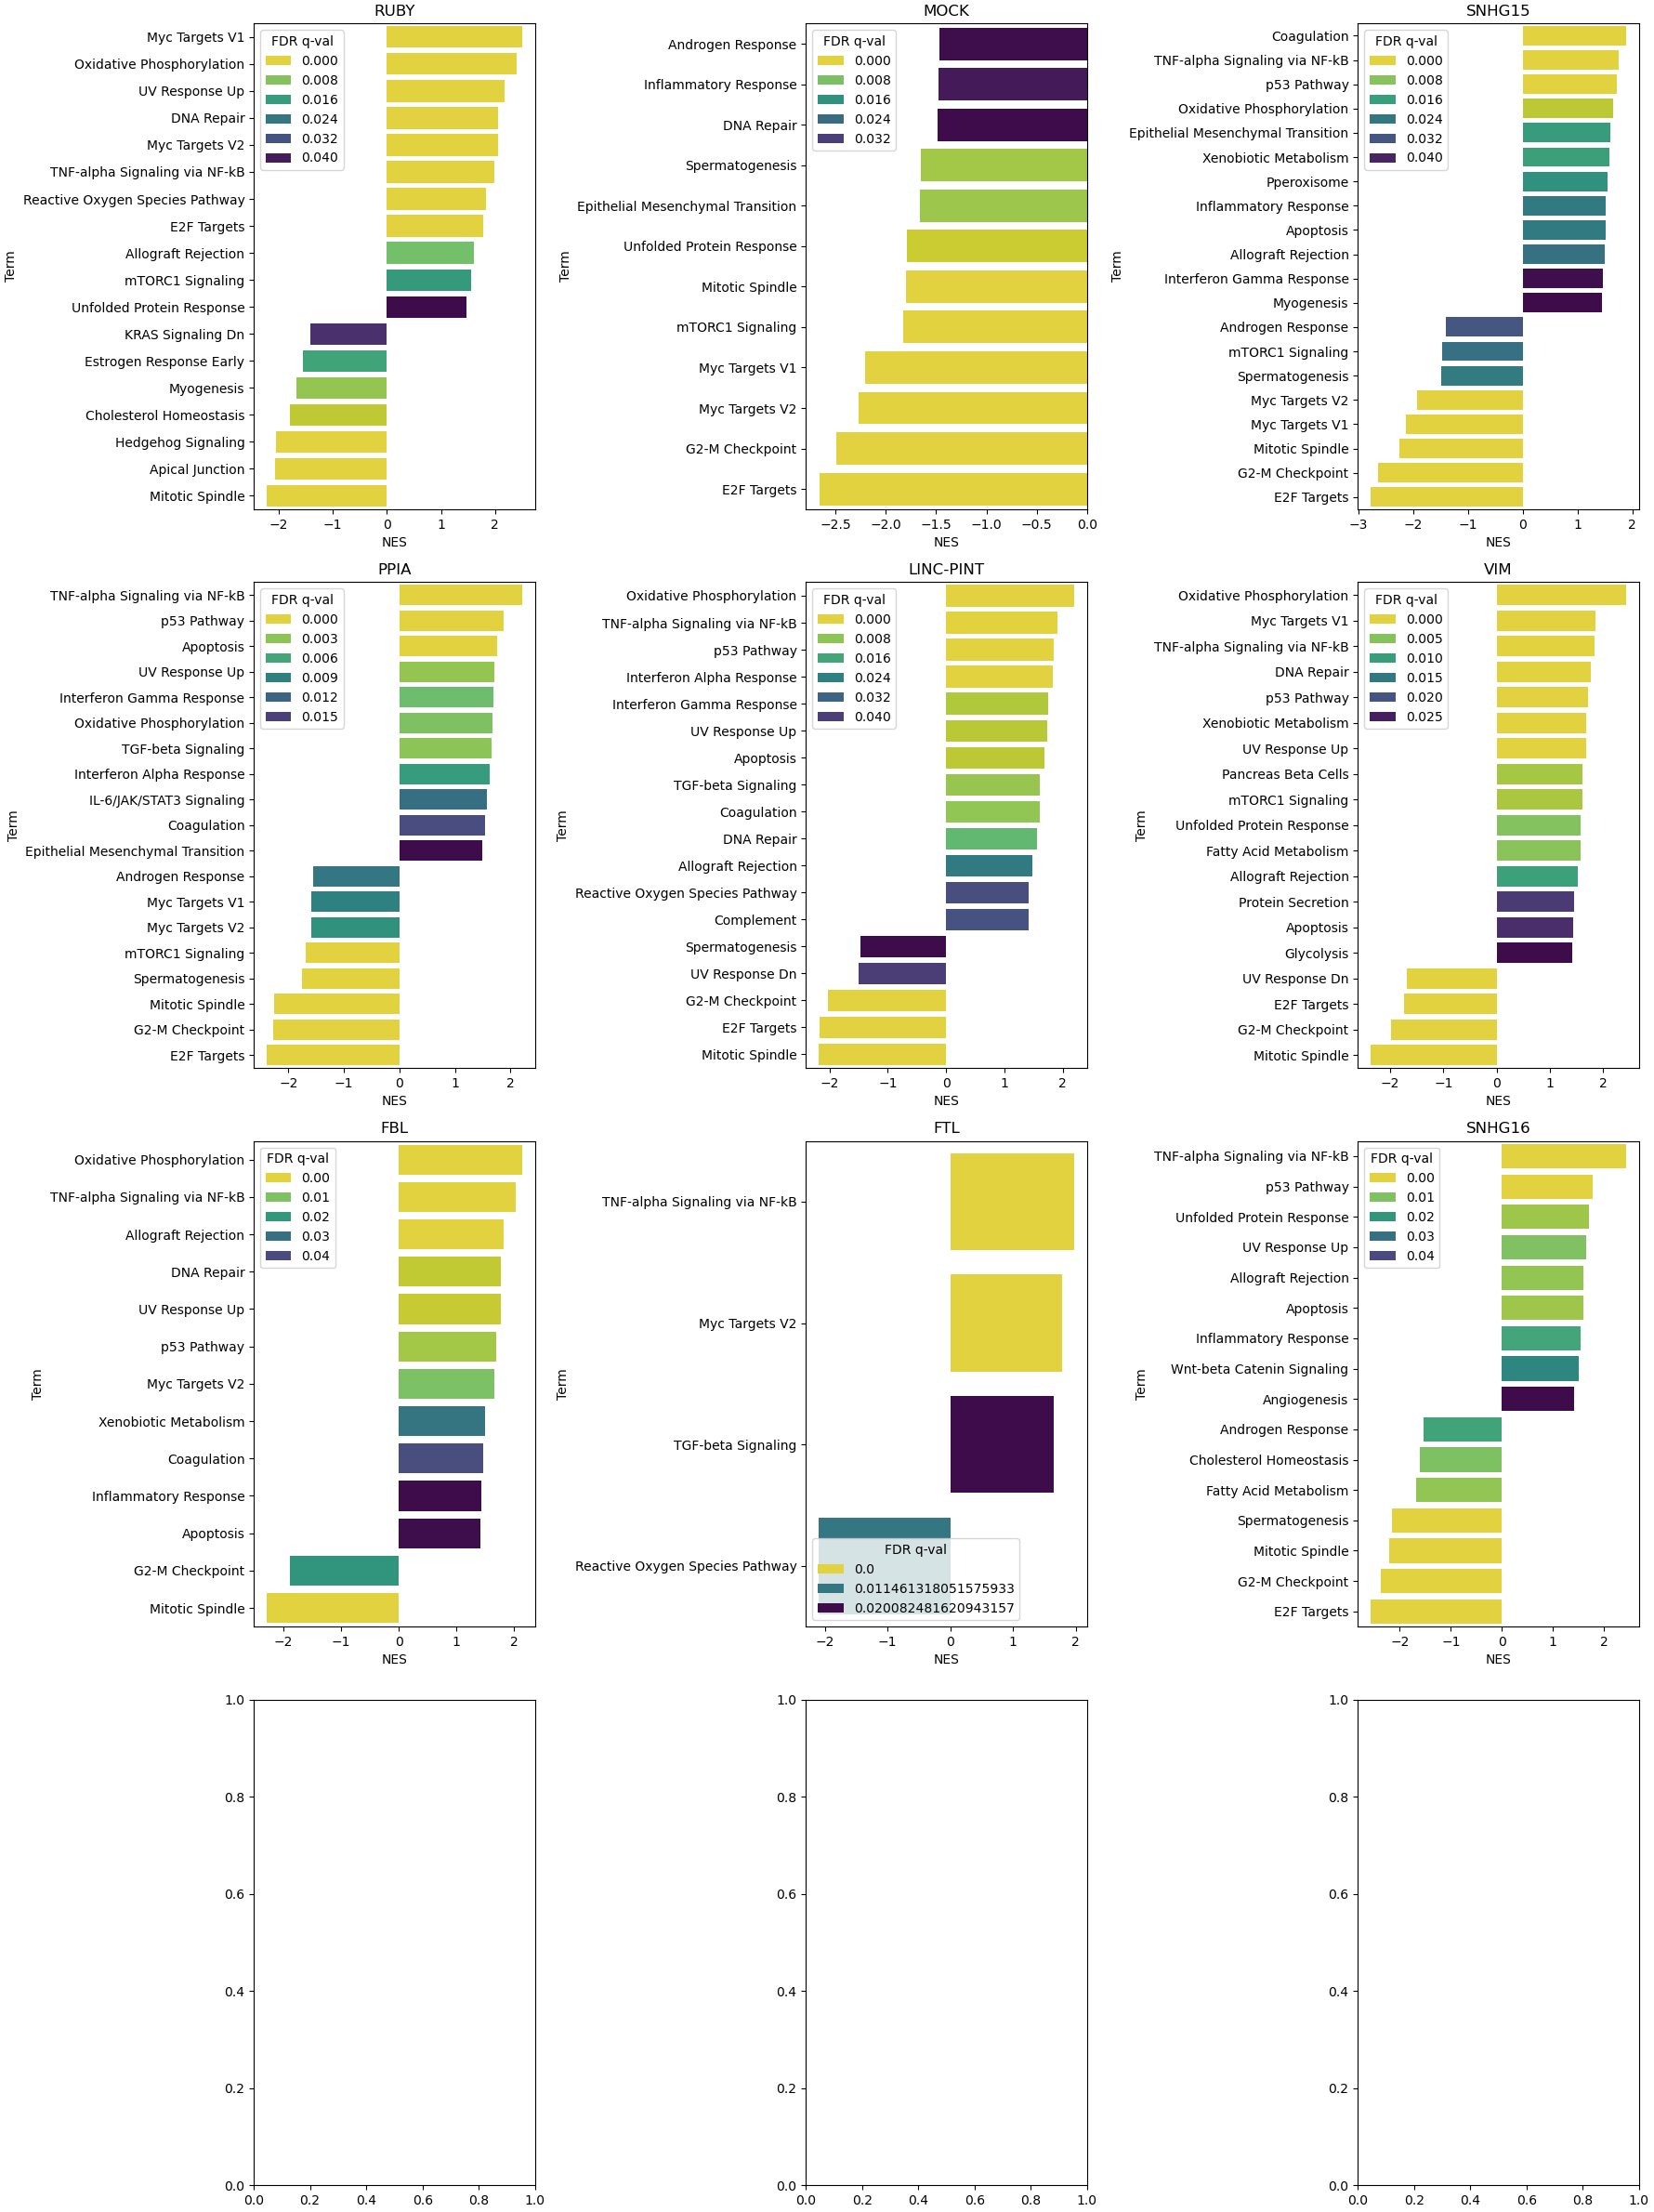

In [188]:
cell_line = 'H1299'
genes = list(tab[cell_line].columns.get_level_values(0).unique())

nrows = 4
ncols = int(np.ceil(len(genes)/nrows))
fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))

for gene, ax in zip(genes, axs.flat):
    res_df = results[(cell_line, gene)].copy()
    res_df = res_df[res_df['FDR q-val'] < 0.05]
    res_df.sort_values('NES', ascending=False, inplace=True)
    sns.barplot(data=res_df.head(20), y='Term', x='NES', ax=ax, hue='FDR q-val', dodge=False, palette='viridis_r')
    ax.set_title(gene)
pl.tight_layout()
pl.show()

In [198]:
res_df = pd.concat(results, axis=0).reset_index(level=(0,1), names=['cell_line', 'gene']).reset_index(drop=True)

In [199]:
mat = res_df.pivot(index='Term', columns=('cell_line', 'gene'), values='NES')
mat = mat.astype(float)

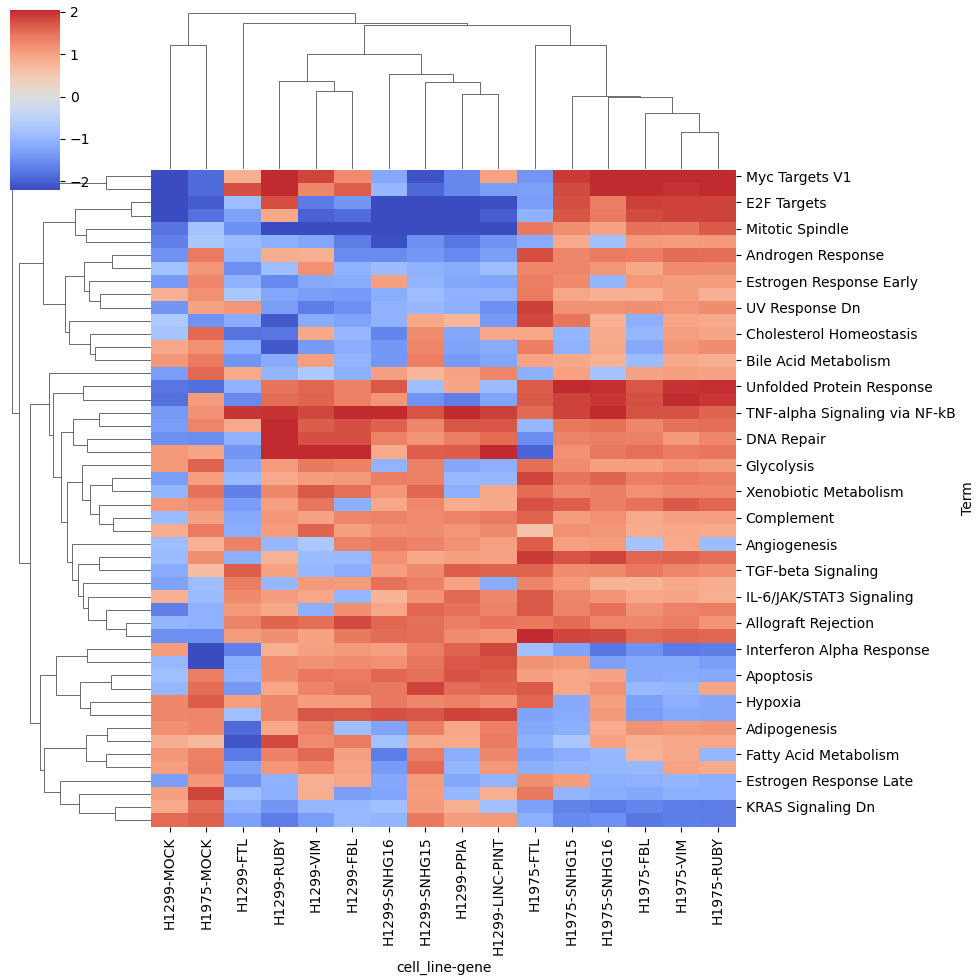

In [201]:
sns.clustermap(mat, cmap='coolwarm', center=0, robust=True)

# Guide-wise DESeq2 analysis

In [269]:
reference = 'NT1'
path = Path("../results/deseq2_results_per_guide/")
files = path.glob("*_vs_*.csv")
res = {}
for file in files:
    df = pd.read_csv(file, index_col=0)
    cell_line = file.stem.split('_')[0]
    test, ref = file.stem.replace(cell_line + '_', '').split('_vs_')
    res[(cell_line, test, ref)] = df

In [270]:
# nrows = 2
# ncols = int(np.ceil(len(res)/nrows))
# fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
# for ax, key in zip(axs.flat, res.keys()):
#     # plot vulcano plot
#     df = res[key]
#     sns.scatterplot(data=df, x='log2FoldChange', y=-np.log10(df['padj']), alpha=0.5, ax=ax)
#     ax.set_title(key)
#     ax.set_xlabel('log2 fold change')
#     ax.set_ylabel('-log10 p-value')
#     ax.axhline(-np.log10(0.05), color='red', linestyle='--')
#     ax.axvline(1, color='blue', linestyle='--')
#     ax.axvline(-1, color='blue', linestyle='--')
# pl.show()

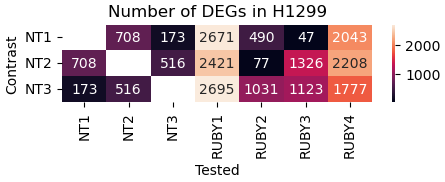

In [285]:
sigs = pd.concat(res, axis=1)
is_sig = (sigs.loc[:, (slice(None), slice(None), slice(None), 'padj')] > 0.05)
is_high = (sigs.loc[:, (slice(None), slice(None), slice(None), 'log2FoldChange')].abs() > 1)
sel = pd.DataFrame(is_sig.values & is_high.values, index=is_sig.index, columns=is_sig.columns)
degs = sel.sum().reset_index().pivot(index='level_1', columns='level_2', values=0)

fig, ax = pl.subplots(figsize=(5, 1))
sns.heatmap(degs.T, robust=True, cmap='rocket', ax=ax, annot=True, fmt='n')
ax.set_xlabel('Tested')
ax.set_ylabel("Contrast")
ax.set_title('Number of DEGs in H1299')
pl.show()

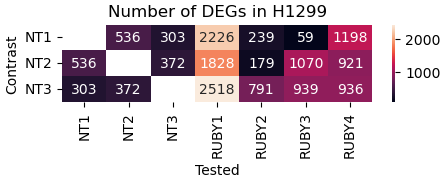

In [286]:
sigs = pd.concat(res, axis=1)
is_sig = (sigs.loc[:, (slice(None), slice(None), slice(None), 'padj')] < 0.05)
is_high = (sigs.loc[:, (slice(None), slice(None), slice(None), 'log2FoldChange')].abs() > 1)
sel = pd.DataFrame(is_sig.values & is_high.values, index=is_sig.index, columns=is_sig.columns)
degs = sel.sum().reset_index().pivot(index='level_1', columns='level_2', values=0)

fig, ax = pl.subplots(figsize=(5, 1))
sns.heatmap(degs.T, robust=True, cmap='rocket', ax=ax, annot=True, fmt='n')
ax.set_xlabel('Tested')
ax.set_ylabel("Contrast")
ax.set_title('Number of DEGs in H1299')
pl.show()

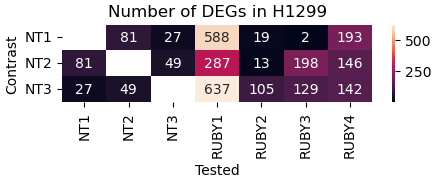

In [291]:
sigs = pd.concat(res, axis=1)
is_sig = (sigs.loc[:, (slice(None), slice(None), slice(None), 'padj')] < 0.01)
is_high = (sigs.loc[:, (slice(None), slice(None), slice(None), 'log2FoldChange')].abs() > 2)
sel = pd.DataFrame(is_sig.values & is_high.values, index=is_sig.index, columns=is_sig.columns)
degs = sel.sum().reset_index().pivot(index='level_1', columns='level_2', values=0)

fig, ax = pl.subplots(figsize=(5, 1))
sns.heatmap(degs.T, robust=True, cmap='rocket', ax=ax, annot=True, fmt='n')
ax.set_xlabel('Tested')
ax.set_ylabel("Contrast")
ax.set_title('Number of DEGs in H1299')
pl.show()

# Debugging the experiment

I see quite different results across guides. Question: is this off-target effects or is it biological variability? Can this difference be explained by Cas13 expression levels?

Which samples to look at?

- H1299: SNHG15 and NT, and Ruby, Mock

In [2]:
# I.e. I want:
sample_names = [
    "99CAS_Mock_R1",
    "99CAS_Mock_R2",
    "99CAS_Mock_R3",
    "99CAS_NT1_R1",
    "99CAS_NT1_R2",
    "99CAS_NT1_R3",
    "99CAS_NT2_R1",
    "99CAS_NT2_R2",
    "99CAS_NT2_R3",
    "99CAS_NT3_R1",
    "99CAS_NT3_R2",
    "99CAS_NT3_R3",
    "99CAS_Ruby1_R1",
    "99CAS_Ruby1_R2",
    "99CAS_Ruby1_R3",
    "99CAS_Ruby2_R1",
    "99CAS_Ruby2_R2",
    "99CAS_Ruby2_R3",
    "99CAS_Ruby3_R1",
    "99CAS_Ruby3_R2",
    "99CAS_Ruby3_R3",
    "99CAS_Ruby4_R1",
    "99CAS_Ruby4_R2",
    "99CAS_Ruby4_R3",
    "99CAS_SNHG15_V1_R1",
    "99CAS_SNHG15_V1_R2",
    "99CAS_SNHG15_V1_R3",
    "99CAS_SNHG15_V2_R1",
    "99CAS_SNHG15_V2_R2",
    "99CAS_SNHG15_V2_R3",
    "99CAS_SNHG15_V3_R1",
    "99CAS_SNHG15_V3_R2",
    "99CAS_SNHG15_V3_R3",
    "99WT_Mock_R1",
    "99WT_Mock_R2",
    "99WT_Mock_R3",
    "99WT_NT1_R1",
    "99WT_NT1_R2",
    "99WT_NT1_R3",
    "99WT_NT2_R1",
    "99WT_NT2_R2",
    "99WT_NT2_R3",
    "99WT_NT3_R1",
    "99WT_NT3_R2",
    "99WT_NT3_R3",
    "99WT_Ruby1_R1",
    "99WT_Ruby1_R2",
    "99WT_Ruby1_R3",
    "99WT_Ruby2_R1",
    "99WT_Ruby2_R2",
    "99WT_Ruby2_R3",
    "99WT_Ruby3_R1",
    "99WT_Ruby3_R2",
    "99WT_Ruby3_R3",
    "99WT_Ruby4_R1",
    "99WT_Ruby4_R2",
    "99WT_Ruby4_R3",
    "99WT_SNHG15_V1_R1",
    "99WT_SNHG15_V1_R2",
    "99WT_SNHG15_V1_R3",
    "99WT_SNHG15_V2_R1",
    "99WT_SNHG15_V2_R2",
    "99WT_SNHG15_V2_R3",
    "99WT_SNHG15_V3_R1",
    "99WT_SNHG15_V3_R2",
    "99WT_SNHG15_V3_R3",
]

In [9]:
sample_metadata = pd.read_csv("../resources/jamie_samples_noduplicates.tsv", sep='\t', header=0, index_col=0)
sample_metadata.set_index("sample_supplier_name", inplace=True)

In [17]:
'|'.join(sample_metadata.loc[sample_names, 'sample'].values)

'8094STDY15826013|8094STDY15826014|8094STDY15826015|8094STDY15826016|8094STDY15826017|8094STDY15826018|8094STDY15826019|8094STDY15826020|8094STDY15826021|8094STDY15826022|8094STDY15826023|8094STDY15826024|8094STDY15826025|8094STDY15826026|8094STDY15826027|8094STDY15826028|8094STDY15826029|8094STDY15826030|8094STDY15826031|8094STDY15826032|8094STDY15826033|8094STDY15826034|8094STDY15826035|8094STDY15826036|8094STDY15826046|8094STDY15826047|8094STDY15826048|8094STDY15826058|8094STDY15826059|8094STDY15826060|8094STDY15826070|8094STDY15826071|8094STDY15826072|8094STDY15826205|8094STDY15826206|8094STDY15826207|8094STDY15826208|8094STDY15826209|8094STDY15826210|8094STDY15826211|8094STDY15826212|8094STDY15826213|8094STDY15826214|8094STDY15826215|8094STDY15826216|8094STDY15826217|8094STDY15826218|8094STDY15826219|8094STDY15826220|8094STDY15826221|8094STDY15826222|8094STDY15826223|8094STDY15826224|8094STDY15826225|8094STDY15826226|8094STDY15826227|8094STDY15826228|8094STDY15826238|8094STDY15826

In [ ]:
8094STDY15826013.fastq.gz
8094STDY15826013_1.fastq.gz
8094STDY15826013_2.fastq.gz
8094STDY15826014.fastq.gz
8094STDY15826014_1.fastq.gz
8094STDY15826014_2.fastq.gz
8094STDY15826015.fastq.gz
8094STDY15826015_1.fastq.gz
8094STDY15826015_2.fastq.gz
8094STDY15826016.fastq.gz
8094STDY15826016_1.fastq.gz
8094STDY15826016_2.fastq.gz
8094STDY15826017.fastq.gz
8094STDY15826017_1.fastq.gz
8094STDY15826017_2.fastq.gz
8094STDY15826018.fastq.gz
8094STDY15826018_1.fastq.gz
8094STDY15826018_2.fastq.gz
8094STDY15826019.fastq.gz
8094STDY15826019_1.fastq.gz
8094STDY15826019_2.fastq.gz
8094STDY15826020.fastq.gz
8094STDY15826020_1.fastq.gz
8094STDY15826020_2.fastq.gz
8094STDY15826021.fastq.gz
8094STDY15826021_1.fastq.gz
8094STDY15826021_2.fastq.gz
8094STDY15826022.fastq.gz
8094STDY15826022_1.fastq.gz
8094STDY15826022_2.fastq.gz
8094STDY15826023.fastq.gz
8094STDY15826023_1.fastq.gz
8094STDY15826023_2.fastq.gz
8094STDY15826024.fastq.gz
8094STDY15826024_1.fastq.gz
8094STDY15826024_2.fastq.gz
8094STDY15826025.fastq.gz
8094STDY15826025_1.fastq.gz
8094STDY15826025_2.fastq.gz
8094STDY15826026.fastq.gz
8094STDY15826026_1.fastq.gz
8094STDY15826026_2.fastq.gz
8094STDY15826027.fastq.gz
8094STDY15826027_1.fastq.gz
8094STDY15826027_2.fastq.gz
8094STDY15826028.fastq.gz
8094STDY15826028_1.fastq.gz
8094STDY15826028_2.fastq.gz
8094STDY15826029.fastq.gz
8094STDY15826029_1.fastq.gz
8094STDY15826029_2.fastq.gz
8094STDY15826030.fastq.gz
8094STDY15826030_1.fastq.gz
8094STDY15826030_2.fastq.gz
8094STDY15826031.fastq.gz
8094STDY15826031_1.fastq.gz
8094STDY15826031_2.fastq.gz
8094STDY15826032.fastq.gz
8094STDY15826032_1.fastq.gz
8094STDY15826032_2.fastq.gz
8094STDY15826033.fastq.gz
8094STDY15826033_1.fastq.gz
8094STDY15826033_2.fastq.gz
8094STDY15826034.fastq.gz
8094STDY15826034_1.fastq.gz
8094STDY15826034_2.fastq.gz
8094STDY15826035.fastq.gz
8094STDY15826035_1.fastq.gz
8094STDY15826035_2.fastq.gz
8094STDY15826036.fastq.gz
8094STDY15826036_1.fastq.gz
8094STDY15826036_2.fastq.gz
8094STDY15826046.fastq.gz
8094STDY15826046_1.fastq.gz
8094STDY15826046_2.fastq.gz
8094STDY15826047.fastq.gz
8094STDY15826047_1.fastq.gz
8094STDY15826047_2.fastq.gz
8094STDY15826048.fastq.gz
8094STDY15826048_1.fastq.gz
8094STDY15826048_2.fastq.gz
8094STDY15826058.fastq.gz
8094STDY15826058_1.fastq.gz
8094STDY15826058_2.fastq.gz
8094STDY15826059.fastq.gz
8094STDY15826059_1.fastq.gz
8094STDY15826059_2.fastq.gz
8094STDY15826060.fastq.gz
8094STDY15826060_1.fastq.gz
8094STDY15826060_2.fastq.gz
8094STDY15826070.fastq.gz
8094STDY15826070_1.fastq.gz
8094STDY15826070_2.fastq.gz
8094STDY15826071.fastq.gz
8094STDY15826071_1.fastq.gz
8094STDY15826071_2.fastq.gz
8094STDY15826072.fastq.gz
8094STDY15826072_1.fastq.gz
8094STDY15826072_2.fastq.gz
8094STDY15826205.fastq.gz
8094STDY15826205_1.fastq.gz
8094STDY15826205_2.fastq.gz
8094STDY15826206.fastq.gz
8094STDY15826206_1.fastq.gz
8094STDY15826206_2.fastq.gz
8094STDY15826207.fastq.gz
8094STDY15826207_1.fastq.gz
8094STDY15826207_2.fastq.gz
8094STDY15826208.fastq.gz
8094STDY15826208_1.fastq.gz
8094STDY15826208_2.fastq.gz
8094STDY15826209.fastq.gz
8094STDY15826209_1.fastq.gz
8094STDY15826209_2.fastq.gz
8094STDY15826210.fastq.gz
8094STDY15826210_1.fastq.gz
8094STDY15826210_2.fastq.gz
8094STDY15826211.fastq.gz
8094STDY15826211_1.fastq.gz
8094STDY15826211_2.fastq.gz
8094STDY15826212.fastq.gz
8094STDY15826212_1.fastq.gz
8094STDY15826212_2.fastq.gz
8094STDY15826213.fastq.gz
8094STDY15826213_1.fastq.gz
8094STDY15826213_2.fastq.gz
8094STDY15826214.fastq.gz
8094STDY15826214_1.fastq.gz
8094STDY15826214_2.fastq.gz
8094STDY15826215.fastq.gz
8094STDY15826215_1.fastq.gz
8094STDY15826215_2.fastq.gz
8094STDY15826216.fastq.gz
8094STDY15826216_1.fastq.gz
8094STDY15826216_2.fastq.gz
8094STDY15826217.fastq.gz
8094STDY15826217_1.fastq.gz
8094STDY15826217_2.fastq.gz
8094STDY15826218.fastq.gz
8094STDY15826218_1.fastq.gz
8094STDY15826218_2.fastq.gz
8094STDY15826219.fastq.gz
8094STDY15826219_1.fastq.gz
8094STDY15826219_2.fastq.gz
8094STDY15826220.fastq.gz
8094STDY15826220_1.fastq.gz
8094STDY15826220_2.fastq.gz
8094STDY15826221.fastq.gz
8094STDY15826221_1.fastq.gz
8094STDY15826221_2.fastq.gz
8094STDY15826222.fastq.gz
8094STDY15826222_1.fastq.gz
8094STDY15826222_2.fastq.gz
8094STDY15826223.fastq.gz
8094STDY15826223_1.fastq.gz
8094STDY15826223_2.fastq.gz
8094STDY15826224.fastq.gz
8094STDY15826224_1.fastq.gz
8094STDY15826224_2.fastq.gz
8094STDY15826225.fastq.gz
8094STDY15826225_1.fastq.gz
8094STDY15826225_2.fastq.gz
8094STDY15826226.fastq.gz
8094STDY15826226_1.fastq.gz
8094STDY15826226_2.fastq.gz
8094STDY15826227.fastq.gz
8094STDY15826227_1.fastq.gz
8094STDY15826227_2.fastq.gz
8094STDY15826228.fastq.gz
8094STDY15826228_1.fastq.gz
8094STDY15826228_2.fastq.gz
8094STDY15826238.fastq.gz
8094STDY15826238_1.fastq.gz
8094STDY15826238_2.fastq.gz
8094STDY15826239.fastq.gz
8094STDY15826239_1.fastq.gz
8094STDY15826239_2.fastq.gz
8094STDY15826240.fastq.gz
8094STDY15826240_1.fastq.gz
8094STDY15826240_2.fastq.gz
8094STDY15826250.fastq.gz
8094STDY15826250_1.fastq.gz
8094STDY15826250_2.fastq.gz
8094STDY15826251.fastq.gz
8094STDY15826251_1.fastq.gz
8094STDY15826251_2.fastq.gz
8094STDY15826252.fastq.gz
8094STDY15826252_1.fastq.gz
8094STDY15826252_2.fastq.gz
8094STDY15826262.fastq.gz
8094STDY15826262_1.fastq.gz
8094STDY15826262_2.fastq.gz
8094STDY15826263.fastq.gz
8094STDY15826263_1.fastq.gz
8094STDY15826263_2.fastq.gz
8094STDY15826264.fastq.gz
8094STDY15826264_1.fastq.gz
8094STDY15826264_2.fastq.gz